In [1]:
import pandas as pd
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from analysis_functions import get_power_data, compute_baseline_stats, detect_power_surges, compute_surge_vs_simpipe_start_endtime_diffs
from analysis_functions import plot_enhanced_visualization

In [44]:
# Data to compare
#data_path = "./data_carbontracker/conf-1/power-run3.xls"                                                                # Tapo Smart plug data measurement
#corresponding_dataset_path = "./data_carbontracker/conf-1/run3.dat"                                                     # Carbontracker/SIMPIPE data

runNr = 4
simpipe_datetime_shift = 120 # minutes to shift data

base_path = "../../data/power-stress-2"
data_path = f"{base_path}/power-run{runNr}.xls"             # Tapo Smart plug data measurement
corresponding_dataset_path = f"{base_path}/run{runNr}.dat"  # Carbontracker/SIMPIPE data

In [45]:
power_data = get_power_data(data_path)                                                                                  # Tapo Smart plug data
carbontracker_simpipe_data = pd.read_csv(corresponding_dataset_path, sep=r'\s+', comment='#', header=0)      # Carbontracker/SIMPIPE data

if simpipe_datetime_shift != 0:
    carbontracker_simpipe_data = carbontracker_simpipe_data.copy()
    # Convert start and stop columns to datetime if they aren't already
    carbontracker_simpipe_data["start"] = pd.to_datetime(carbontracker_simpipe_data["start"])
    carbontracker_simpipe_data["stop"] = pd.to_datetime(carbontracker_simpipe_data["stop"])
    # Now apply the time shift
    carbontracker_simpipe_data["start"] += pd.Timedelta(minutes=simpipe_datetime_shift)
    carbontracker_simpipe_data["stop"] += pd.Timedelta(minutes=simpipe_datetime_shift)

In [46]:
# runNr 1
#min_duration_minutes = 60           # minimum duration (s) for a surge to be considered
#surge_threshold_multiplier = 1.05   # threshold multiplier for surge detection (relative to baseline)

# runNr 2
#min_duration_minutes = 60           # minimum duration (s) for a surge to be considered
#surge_threshold_multiplier = 1.04   # threshold multiplier for surge detection (relative to baseline)

# runNr 3
#min_duration_minutes = 60           # minimum duration (s) for a surge to be considered
#surge_threshold_multiplier = 1.01   # threshold multiplier for surge detection (relative to baseline)

baseline_stats = compute_baseline_stats(df=power_data, percentile_threshold=70, print_stats=True)
surge_periods, surge_threshold = detect_power_surges(power_data, baseline_stats, min_duration_minutes=min_duration_minutes, surge_threshold_multiplier=surge_threshold_multiplier)

     compute_baseline_stats -- Baseline analysis...
      Power threshold for baseline: 211.0 W
      Baseline periods: 213 out of 287 (74.2%)
      Mean baseline power: 205.8 W
      Median baseline power: 206.0 W
      Std baseline power: 3.2 W
      Power range: 198.0 - 211.0 W
      Mean baseline energy per period: 0.017148 kWh
      Total baseline energy: 3.6525 kWh



Carbontracker period: 2026-10-01 08:50:08 to 2026-10-01 11:50:14
Power data period: 2026-09-30 14:00:00 to 2026-10-01 13:50:00


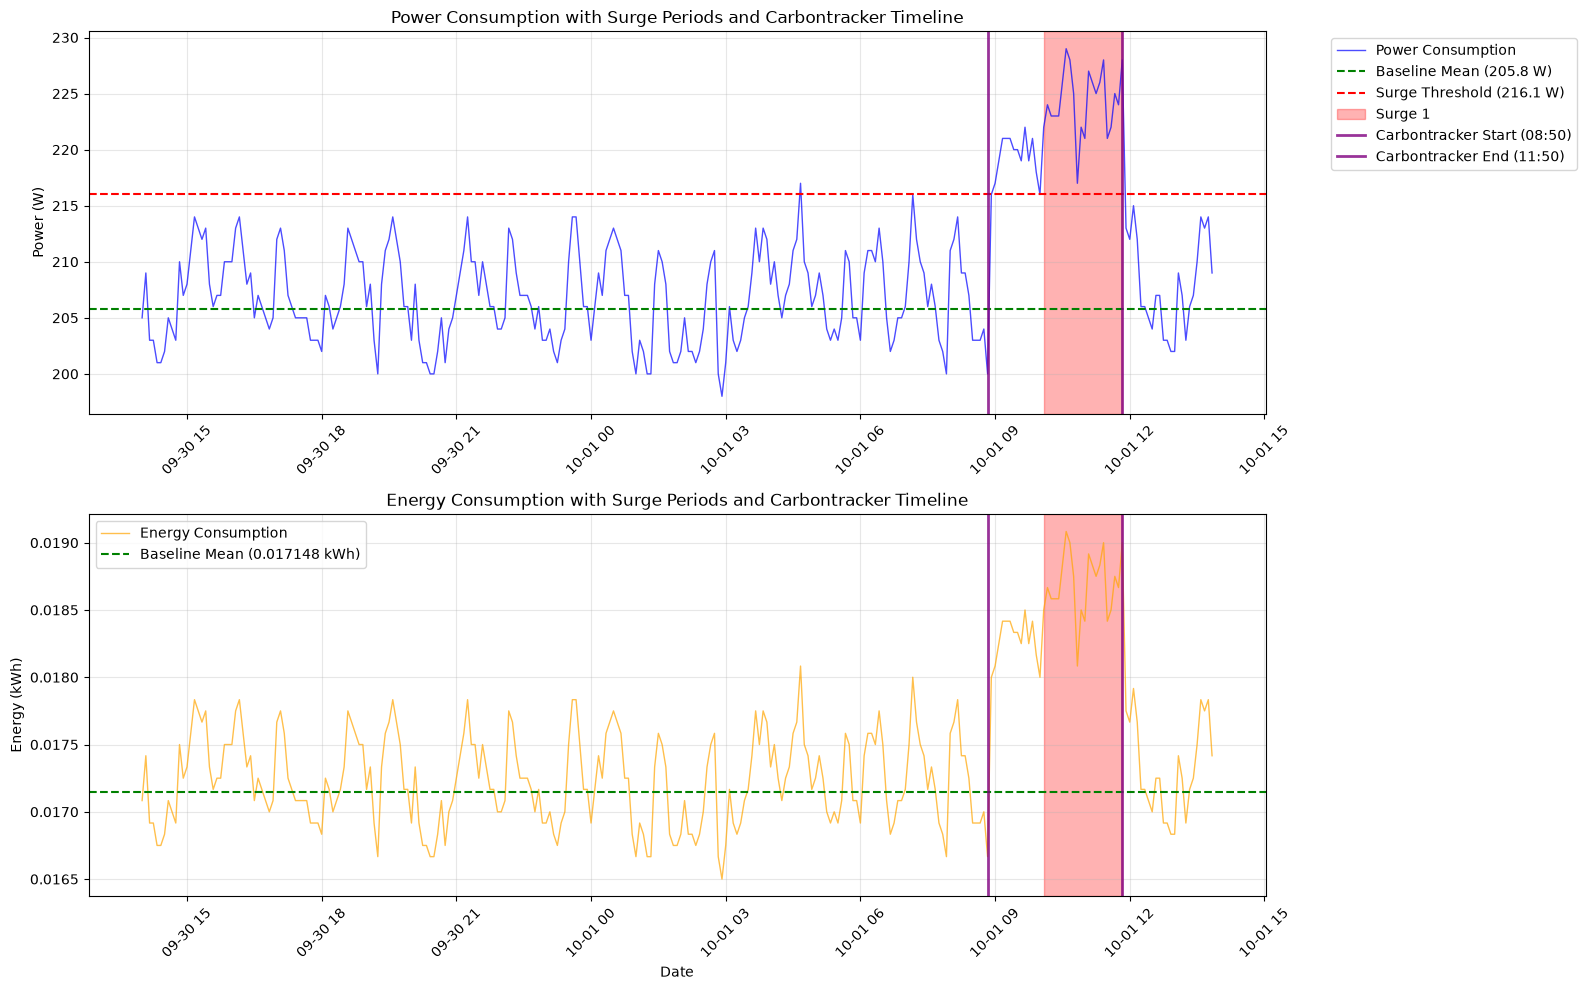

=== CARBONTRACKER vs POWER SURGE ANALYSIS ===
Carbontracker monitoring period: 08:50 - 11:50
Carbontracker duration: 3.00 hours

Overlap analysis with detected surge periods:
  Surge 1: 100.0% overlap (105.0/105.0 minutes)
    Surge: 10:05 - 11:50
    Overlap: 10:05 - 11:50

Power statistics during Carbontracker period:
  Average power: 222.4 W
  Peak power: 229.0 W
  Total energy: 0.6671 kWh
  Carbontracker reported energy: 0.4270 kWh
  Energy difference: 0.2401 kWh


In [47]:
plot_enhanced_visualization(carbontracker_simpipe_data, power_data, baseline_stats, surge_periods, surge_threshold)

In [48]:
compute_surge_vs_simpipe_start_endtime_diffs(carbontracker_simpipe_data=carbontracker_simpipe_data, surge_periods=surge_periods)

=== TIME DIFFERENCE ANALYSIS ===
Carbontracker start time: 2026-10-01 08:50:08
Carbontracker stop time: 2026-10-01 11:50:14
Carbontracker duration: 180.1 minutes

Surge 1:
  Surge start: 2026-10-01 10:05:00
  Surge end: 2026-10-01 11:50:00
  Start time difference from carbontracker start:
    +1.25 hours (74.9 minutes) AFTER carbontracker start
  End time difference from carbontracker stop:
    -0.00 hours (0.2 minutes) BEFORE carbontracker stop

=== TIMING RELATIONSHIPS SUMMARY ===
Surges starting before carbontracker         : 0
Surges overlapping with carbontracker period : 1
Surges starting after carbontracker          : 0

Closest surge to carbontracker start      : Surge 1
Time difference: 74.9 minutes
This surge OVERLAPS with carbontracker execution period


# Analysis of time diffs

...

We therefore compute the differences
* Dstart = diff(simpipe_start - estimated_power_surge_start)
* Dend = diff(simpipe_end - estimated_power_surge_end)
* Delta = (simpipe_start - simpipe_end) - Dend
* Kappa = (simpipe_start - simpipe_end) - Delta

In [49]:
# Data for surge time differences.
# data contains table of surge time differences between Tapo Smart plug and Carbontracker/SIMPIPE for all runs.
# Columns: Configuration, RunNr, Start_Time_Diff_minutes, End_Time_Diff_meconds, SIMPIPE_Duration_minutes
surge_time_diffs = pd.read_csv("../../data/power-stress-2/surge_time_diffs.dat", sep=r'\s+', comment='#', header=0)
# isna
nan_values = surge_time_diffs[surge_time_diffs.isna()["duration"]]
# remove NaN values
surge_time_diffs = surge_time_diffs.dropna()
# compute delta = End_Time_Diff_meconds - Start_Time_Diff_minutes
surge_time_diffs['Delta'] = surge_time_diffs['duration'] - surge_time_diffs['endDiff']
# compute tapo_power_duration
surge_time_diffs['tapo_power_duration'] = surge_time_diffs['startDiff'] - surge_time_diffs['endDiff'] + surge_time_diffs['duration']
# duration diff (diff between estimated power surge in Tapo data and SIMPIPE data)
surge_time_diffs['tapo_simpipe_duration_diff'] = surge_time_diffs['duration'] - surge_time_diffs['tapo_power_duration']

In [50]:
surge_time_diffs

,configuration,runNr,startDiff,endDiff,duration,Delta,tapo_power_duration,tapo_simpipe_duration_diff
0,power-surge,1,0.06,-0.03,180.1,180.13,180.19,-0.09
1,power-surge,2,0.08,-0.01,180.1,180.11,180.19,-0.09
2,power-surge,3,0.06,-0.03,180.1,180.13,180.19,-0.09
3,power-surge,4,0.08,0.00,180.1,180.10,180.18,-0.08


In [51]:
surge_time_diffs.startDiff.mean()
#surge_time_diffs.endDiff.mean()

np.float64(0.07)

In [43]:
baseline_stats

{'threshold_power': np.float64(209.0),
 'baseline_periods': 202,
 'total_periods': 288,
 'baseline_percentage': 70.13888888888889,
 'mean_power': np.float64(203.45049504950495),
 'median_power': np.float64(203.0),
 'std_power': np.float64(3.063186120111384),
 'min_power': np.int64(197),
 'max_power': np.int64(209),
 'mean_energy': np.float64(0.016954207920792077),
 'total_baseline_energy': np.float64(3.4247499999999995)}